In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('../data/raw/water_potability.csv')


df = df.dropna(subset=['Potability'])

X = df.drop('Potability', axis=1)
y = df['Potability']

print("Shape X:", X.shape)
print("Distribución y:\n", y.value_counts())

Shape X: (3276, 9)
Distribución y:
 Potability
0    1998
1    1278
Name: count, dtype: int64


In [3]:
np.random.seed(42)

X_missing = X.copy()
mask = np.random.rand(*X_missing.shape) < 0.10
X_missing[mask] = np.nan

pct_faltantes = X_missing.isnull().sum().sum() / X_missing.size * 100
print(f"Valores faltantes introducidos: {pct_faltantes:.2f}%")

Valores faltantes introducidos: 14.56%


In [4]:
def evaluar_modelo(X_imp, y, nombre):
    X_train, X_test, y_train, y_test = train_test_split(
        X_imp, y, test_size=0.2, random_state=42, stratify=y
    )
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    modelo = LogisticRegression(max_iter=1000, random_state=42)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"\n{'='*40}")
    print(f"Método: {nombre}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(classification_report(y_test, y_pred))
    
    return {'Método': nombre, 'Accuracy': round(acc, 4), 'F1-score': round(f1, 4)}

In [5]:
imputer_media = SimpleImputer(strategy='mean')
X_media = pd.DataFrame(
    imputer_media.fit_transform(X_missing),
    columns=X.columns
)
resultado_media = evaluar_modelo(X_media, y, 'Imputación por Media')


Método: Imputación por Media
Accuracy:  0.6098
F1-score:  0.0000
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       400
           1       0.00      0.00      0.00       256

    accuracy                           0.61       656
   macro avg       0.30      0.50      0.38       656
weighted avg       0.37      0.61      0.46       656



c:\Users\Bianca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bianca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bianca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [6]:
imputer_knn = KNNImputer(n_neighbors=5)
X_knn = pd.DataFrame(
    imputer_knn.fit_transform(X_missing),
    columns=X.columns
)
resultado_knn = evaluar_modelo(X_knn, y, 'Imputación KNN')


Método: Imputación KNN
Accuracy:  0.6098
F1-score:  0.0000
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       400
           1       0.00      0.00      0.00       256

    accuracy                           0.61       656
   macro avg       0.30      0.50      0.38       656
weighted avg       0.37      0.61      0.46       656



c:\Users\Bianca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bianca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bianca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [7]:
resultados = pd.DataFrame([resultado_media, resultado_knn])
print(resultados)

# Guardar en CSV
resultados.to_csv('../results/tables/comparacion_metodos.csv', index=False)
print("\nTabla guardada en results/tables/comparacion_metodos.csv")

                 Método  Accuracy  F1-score
0  Imputación por Media    0.6098       0.0
1        Imputación KNN    0.6098       0.0

Tabla guardada en results/tables/comparacion_metodos.csv


C:\Users\Bianca\AppData\Local\Temp\ipykernel_22056\4229667459.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(resultados['Método'], rotation=15, ha='right')
C:\Users\Bianca\AppData\Local\Temp\ipykernel_22056\4229667459.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(resultados['Método'], rotation=15, ha='right')


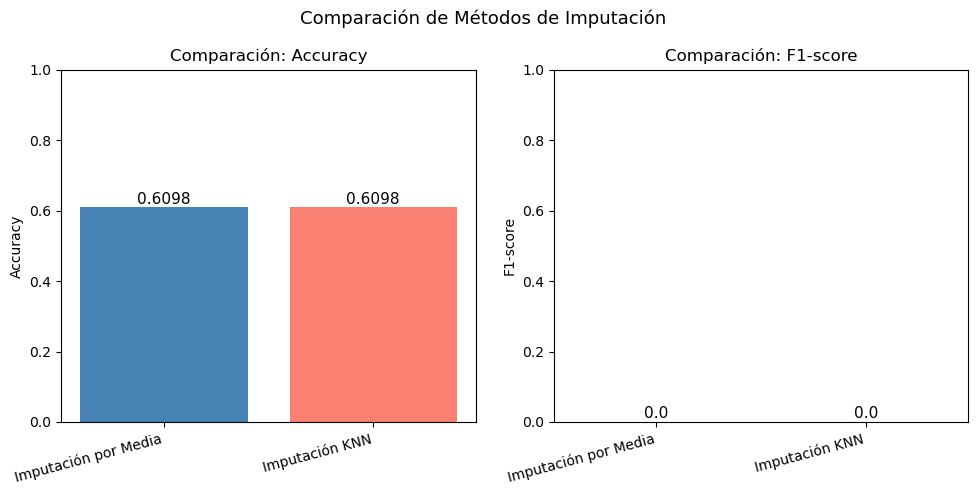

Figura guardada en results/figures/comparacion_metodos.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

metricas = ['Accuracy', 'F1-score']
colores = ['steelblue', 'salmon']

for i, metrica in enumerate(metricas):
    axes[i].bar(resultados['Método'], resultados[metrica], color=colores)
    axes[i].set_title(f'Comparación: {metrica}')
    axes[i].set_ylabel(metrica)
    axes[i].set_ylim(0, 1)
    axes[i].set_xticklabels(resultados['Método'], rotation=15, ha='right')
    for j, val in enumerate(resultados[metrica]):
        axes[i].text(j, val + 0.01, str(val), ha='center', fontsize=11)

plt.suptitle('Comparación de Métodos de Imputación', fontsize=13)
plt.tight_layout()
plt.savefig('../results/figures/comparacion_metodos.png', dpi=150)
plt.show()
print("Figura guardada en results/figures/comparacion_metodos.png")

In [9]:
X_knn['Potability'] = y.values
X_knn.to_csv('../data/processed/water_potability_knn.csv', index=False)

X_media['Potability'] = y.values
X_media.to_csv('../data/processed/water_potability_media.csv', index=False)

print("Datasets procesados guardados en data/processed/")

Datasets procesados guardados en data/processed/
